<a href="https://colab.research.google.com/github/DylanWeidner/Housing_Prices_King_County_DylanWeidner_ProjectShowcase/blob/main/Housing_Prices_King_County_DylanWeidner_ProjectShowcase.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Dylan Weidner
#Data Science with AI for Beginners (tdbeb) contest 1
#Housing Prices King County


# Introduction

The purpose of this project is to explore the King County housing sales dataset, and train models to predict housing prices in this Couunty. There are easy drop downs for each section of the project.

#Imports for Project


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import geopandas as gpd
import contextily as ctx
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from google.colab import drive
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from geopy.distance import geodesic
from sklearn.preprocessing import StandardScaler


In [17]:
pip install geopandas contextily

#Import the dataset, and explore the data

CSV import, and looking at the first five rows of the dataset.

Dataset also available at https://www.kaggle.com/datasets/harlfoxem/housesalesprediction

In [18]:
#Import dataset from my google drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/_Intro to data science/Project1/kc_house_data.csv'
df = pd.read_csv(file_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
pd.set_option('display.max_columns', None)

In [20]:
df.head(3)

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062


Look at some statistics about the data.

In [21]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


Looking at the data types of each feature

In [22]:
df.dtypes.to_frame().T

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,int64,object,float64,int64,float64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,int64,int64


We have 21613 Records with 21 features in our dataset.

In [23]:
df.shape

(21613, 21)

Looking at the datatypes of our data.
The date field is not a datetime datatype. We will want to address that.


In [24]:
df.dtypes.to_frame().T

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,int64,object,float64,int64,float64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,float64,int64,int64


Look at how many unique values are in each column

In [25]:
df.nunique(dropna=False).to_frame().T

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,21436,372,4028,13,30,1038,9782,6,2,5,5,12,946,306,116,70,70,5034,752,777,8689


We have no Null values per the two lines below

In [26]:
df.isnull().sum().to_frame().T

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [27]:
df.isna().sum().to_frame().T

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


#Data Wrangling, and building dataframes


---

We will try to clean bad data and fix any issues with the dataset. We will also be making several dataframes to test different engineered features and see their affect on our models.

We will drop the id column as it should not have major predictive properties

In [28]:
df = df.drop(columns=["id"])

The date column is an Object data type. We will extract the Year and month from it to try and get useful data.

In [29]:
df['date'].head().to_frame().T

,0,1,2,3,4
date,20141013T000000,20141209T000000,20150225T000000,20141209T000000,20150218T000000


In [30]:
df['date'] = pd.to_datetime(df['date'])

In [31]:
df['date'].head().to_frame().T

,0,1,2,3,4
date,2014-10-13,2014-12-09,2015-02-25,2014-12-09,2015-02-18


In [32]:
df['year'] = df['date'].dt.year

In [33]:
df['month'] = df['date'].dt.month

In [34]:
df['date'].dt.year.value_counts()

,count
date,
2014,14633
2015,6980


In [35]:
df['date'].dt.month.value_counts().to_frame().T

date,5,4,7,6,8,10,3,9,12,11,2,1
count,2414,2231,2211,2180,1940,1878,1875,1774,1471,1411,1250,978


We will now drop the date column, as we have the usefule data in year and month

In [36]:
df = df.drop(columns=['date'])

In [37]:
df.columns.to_frame().T

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,year,month
0,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,year,month


We will then create Dummy columns for month and year

In [38]:
df = pd.get_dummies(df, columns=['month'], drop_first=True)
df = pd.get_dummies(df, columns=['year'], drop_first=True)

We had a record with 33 bedrooms. Let's look at it and address it

In [39]:
num33bedrooms = df[df['bedrooms'] == 33]['bedrooms'].count()
print(f'There are {num33bedrooms} houses with 33 bedrooms')

There are 1 houses with 33 bedrooms


After locating this record, it seems to make no sense with the sqft and bedrooms values. We will drop it, as it was likely a mistake.


In [40]:
df.iloc[15870].to_frame().T

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
15870,640000.0,33,1.75,1620,6000,1.0,0,0,5,7,1040,580,1947,0,98103,47.6878,-122.331,1330,4700,False,False,False,False,True,False,False,False,False,False,False,False


In [41]:
# drop record
df = df.drop(index=15870)

In [42]:
# Check that the record is gone
num33bedrooms = df[df['bedrooms'] == 33]['bedrooms'].count()
print(f'There are {num33bedrooms} houses with 33 bedrooms')

There are 0 houses with 33 bedrooms


In [43]:
#look at 11 bedrooms record
df[df['bedrooms'] == 11]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
8757,520000.0,11,3.0,3000,4960,2.0,0,0,3,7,2400,600,1918,1999,98106,47.556,-122.363,1420,4960,False,False,False,False,False,False,True,False,False,False,False,False


In [44]:
#remove this record as well, as house size and price don't correlate with 11 bedrooms
df = df.drop(index=8757)

In [45]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161100e+04,21611.000000,21611.000000,21611.000000,2.161100e+04,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000,21611.000000
mean,5.400844e+05,3.369118,2.114733,2079.878442,1.510786e+04,1.494308,0.007542,0.234325,3.409375,7.656934,1788.397020,291.481421,1971.008699,84.317570,98077.937347,47.560047,-122.213884,1986.609088,12769.190320
std,3.671435e+05,0.906518,0.770171,918.456742,4.142232e+04,0.539992,0.086521,0.766350,0.650677,1.175496,828.103196,442.586196,29.372103,401.486212,53.506890,0.138567,0.140829,685.397631,27305.336262
min,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.217250e+05,3.000000,1.750000,1426.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.470950,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.620000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068850e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.500000
max,7.700000e+06,10.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [46]:
# We have 13 records with 0 bedrooms
len(df[df["bedrooms"] == 0])

13

In [47]:
# drop 0 bedroom records
df = df[df['bedrooms'] != 0]

In [48]:
# Check they are gone
df[df['bedrooms'] == 0]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015


In [49]:
# check on 0 bathroom records
df[df['bathrooms'] == 0]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
1149,75000.0,1,0.0,670,43377,1.0,0,0,3,3,670,0,1966,0,98022,47.2638,-121.906,1160,42882,True,False,False,False,False,False,False,False,False,False,False,True
5832,280000.0,1,0.0,600,24501,1.0,0,0,2,3,600,0,1950,0,98045,47.5316,-121.749,990,22549,False,False,False,False,False,False,False,False,False,True,False,False
10481,484000.0,1,0.0,690,23244,1.0,0,0,4,7,690,0,1948,0,98053,47.6429,-121.955,1690,19290,False,False,False,False,False,False,False,True,False,False,False,False


In [50]:
# we will remove these 0 bathroom records as I assume this is incorrect
df = df[df['bathrooms'] != 0]

In [51]:
# Look at records with more than 3 bathrooms
df[df['bathrooms'] > 3].groupby('bathrooms')['bathrooms'].value_counts()

,count
bathrooms,
3.25,589
3.50,731
3.75,155
4.00,136
4.25,79
4.50,100
4.75,23
5.00,21
5.25,13


In [52]:
df[df['bathrooms'] > 7]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
7252,7700000.0,6,8.00,12050,27600,2.5,0,3,4,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800,False,False,False,False,False,False,False,False,True,False,False,False
8546,450000.0,9,7.50,4050,6504,2.0,0,0,3,7,4050,0,1996,0,98144,47.5923,-122.301,1448,3866,False,False,False,False,False,False,True,False,False,False,False,False
9254,6885000.0,6,7.75,9890,31374,2.0,0,4,3,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730,False,False,False,False,False,False,False,True,False,False,False,False
12777,2280000.0,7,8.00,13540,307752,3.0,0,4,3,12,9410,4130,1999,0,98053,47.6675,-121.986,4850,217800,False,False,False,True,False,False,False,False,False,False,False,False


In [53]:
df[(df['bathrooms'] < 7) & (df['bathrooms'] > 5)]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
1164,5110800.0,5,5.25,8010,45517,2.0,1,4,3,12,5990,2020,1999,0,98033,47.6767,-122.211,3430,26788,False,False,False,False,False,False,False,False,True,False,False,False
1315,5300000.0,6,6.00,7390,24829,2.0,1,4,4,12,5000,2390,1991,0,98040,47.5631,-122.210,4320,24619,False,False,True,False,False,False,False,False,False,False,False,True
2626,4500000.0,5,5.50,6640,40014,2.0,1,4,3,12,6350,290,2004,0,98155,47.7493,-122.280,3030,23408,False,False,False,False,False,False,True,False,False,False,False,False
3020,2525000.0,4,5.50,6930,45100,1.0,0,0,4,11,4310,2620,1950,1991,98006,47.5547,-122.144,2560,37766,False,False,False,False,False,False,False,True,False,False,False,False
3100,1500000.0,4,5.50,6550,217374,1.0,0,0,3,11,5400,1150,2006,0,98058,47.4302,-122.095,4110,50378,False,False,False,False,False,False,True,False,False,False,False,False
3121,1320000.0,4,5.25,6110,10369,2.0,0,0,3,11,6110,0,2005,0,98059,47.5285,-122.135,4190,10762,False,False,False,False,False,False,False,False,False,True,False,False
4024,800000.0,7,6.75,7480,41664,2.0,0,2,3,11,5080,2400,1953,0,98166,47.4643,-122.368,2810,33190,False,False,False,False,False,False,False,False,True,False,False,False
4035,2150000.0,8,6.00,4340,9415,2.0,0,0,3,8,4340,0,1967,0,98004,47.6316,-122.202,2050,9100,False,False,False,False,False,False,False,False,True,False,False,False
4149,4000000.0,4,5.50,7080,16573,2.0,0,0,3,12,5760,1320,2008,0,98039,47.6151,-122.224,3140,15996,False,False,False,False,False,False,False,False,True,False,False,False
4411,5570000.0,5,5.75,9200,35069,2.0,0,0,3,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345,False,False,False,False,False,False,True,False,False,False,False,False


In [54]:
# other bathrooms values look normal
# we will look at the sq foot lot column
df[df['sqft_lot'] == df['sqft_lot'].max()]
# value is normal as it is a farm

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
1719,700000.0,4,1.0,1300,1651359,1.0,0,3,4,6,1300,0,1920,0,98022,47.2313,-122.023,2560,425581,False,True,False,False,False,False,False,False,False,False,False,True


In [55]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.159500e+04,21595.000000,21595.000000,21595.000000,2.159500e+04,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000,21595.000000
mean,5.401992e+05,3.371475,2.115802,2080.300579,1.510030e+04,1.494096,0.007548,0.234313,3.409771,7.657976,1788.603195,291.697384,1971.003241,84.380042,98077.949386,47.560087,-122.213970,1986.676962,12759.017782
std,3.671501e+05,0.902643,0.768992,918.121966,4.141445e+04,0.539686,0.086553,0.766422,0.650480,1.173237,827.771962,442.678981,29.373926,401.628362,53.514939,0.138555,0.140724,685.236784,27275.598218
min,7.800000e+04,1.000000,0.500000,370.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,3.000000,370.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,3.220000e+05,3.000000,1.750000,1430.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471100,-122.328000,1490.000000,5100.000000
50%,4.500000e+05,3.000000,2.250000,1910.000000,7.620000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.231000,1840.000000,7620.000000
75%,6.450000e+05,4.000000,2.500000,2550.000000,1.068600e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,7.700000e+06,10.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


In [56]:
# Value seems normal
df[df['sqft_living'] == df['sqft_living'].max()]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
12777,2280000.0,7,8.0,13540,307752,3.0,0,4,3,12,9410,4130,1999,0,98053,47.6675,-121.986,4850,217800,False,False,False,True,False,False,False,False,False,False,False,False


In [57]:
df['waterfront'].unique()

array([0, 1])

In [58]:
df['view'].unique()

array([0, 3, 4, 2, 1])

In [59]:
#most houses seem to get sold without being viewed
df['view'].value_counts()

,count
view,
0,19473
2,961
3,510
1,332
4,319


In [60]:
df['condition'].value_counts()

,count
condition,
3,14019
4,5677
5,1700
2,170
1,29


In [61]:
df['grade'].value_counts()

,count
grade,
7,8972
8,6065
9,2615
6,2038
10,1134
11,399
5,242
12,89
4,27


In [62]:
meanpricebyzip = round(df.groupby('zipcode')['price'].mean(), 2)
meanpricebyzip = meanpricebyzip.to_frame()

<Axes: xlabel='price', ylabel='zipcode'>

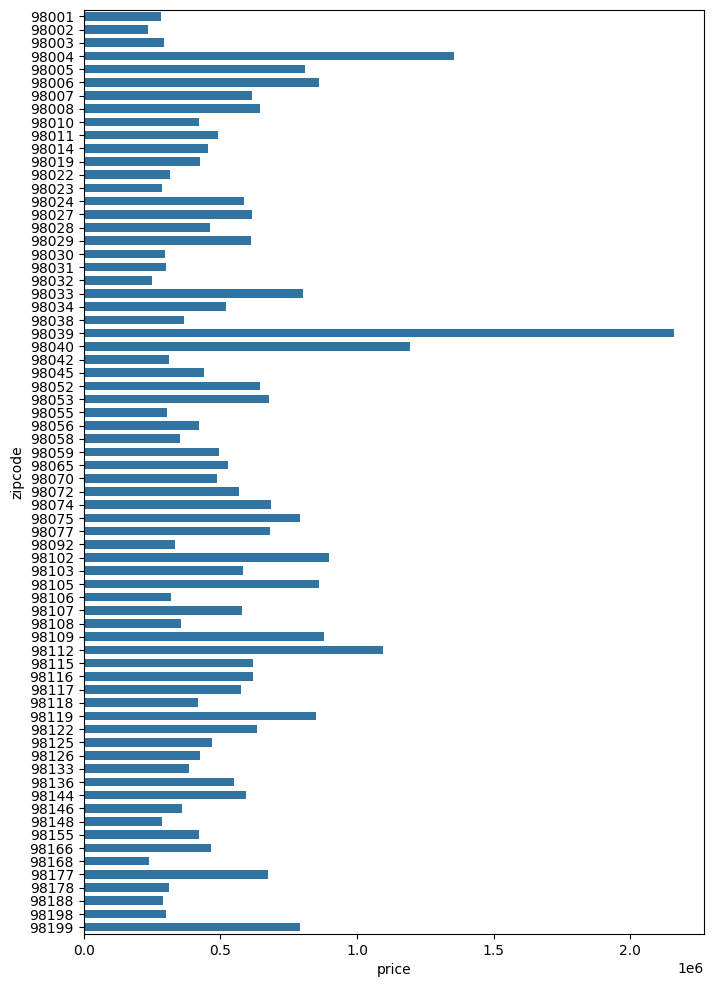

In [63]:
plt.figure(figsize=(8,12))
sns.barplot(data=meanpricebyzip, x='price', y='zipcode', gap=0.2, orient="h")

In [64]:
df[['price', 'zipcode']].corr()

,price,zipcode
price,1.000000,-0.053442
zipcode,-0.053442,1.000000


There is a visual correlation between zipcode and house price.

We will use get_dummies to create dummy columns for model training

In [65]:
df_zips = df.copy()

In [66]:
df_zips = pd.get_dummies(df_zips, columns=['zipcode'], drop_first=True)

In [67]:
df_zips.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Fal

In [68]:
df_zipswat = df_zips.copy()

In [69]:
df_zipswat = pd.get_dummies(df_zipswat, columns=['waterfront'], drop_first=True)

In [70]:
df_zipswat.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1
0,221900.0,3,1.00,1180,5650,1.0,0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False
1,538000.0,3,2.25,2570,7242,2.0,0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,180000.0,2,1.00,770,10000,1.0,0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,604000.0,4,3.00,1960,5000,1.0,0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False
4,510000.0,3,2.00,1680,8080,1.0,0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False

In [71]:
df_zipswatview = df_zipswat.copy()

In [72]:
df_zipswatview = pd.get_dummies(df_zipswatview, columns=['view'], drop_first=True)

In [73]:
df_zipswatview.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1,view_1,view_2,view_3,view_4
0,221900.0,3,1.00,1180,5650,1.0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False
1,538000.0,3,2.25,2570,7242,2.0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,180000.0,2,1.00,770,10000,1.0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,604000.0,4,3.00,1960,5000,1.0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,510000.0,3,2.00,1680,8080,1.0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,Fals

In [74]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,True,False
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503,True,False,False,False,False,False,False,False,False,False,False,True


In [75]:
df_zipswatview_ren = df_zipswatview.copy()

In [76]:
df_zipswatview_ren['yr_renovated'].value_counts()

,count
yr_renovated,
0,20682
2014,91
2013,37
2003,36
2005,35
...,...
1948,1
1951,1
1959,1


In [77]:
#Changed the yr_renovated column to be a yes or no, rather than the year
was_renovated = []

for ren in df['yr_renovated']:
  if ren > 0:
    was_renovated.append(1)
  else:
    was_renovated.append(0)




In [78]:
df_zipswatview_ren['renovated'] = was_renovated


In [79]:
df_zipswatview_ren = pd.get_dummies(df_zipswatview_ren, columns=['renovated'], drop_first=True)

In [80]:
df_zipswatview_ren.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1,view_1,view_2,view_3,view_4,renovated_1
0,221900.0,3,1.00,1180,5650,1.0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False
1,538000.0,3,2.25,2570,7242,2.0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True
2,180000.0,2,1.00,770,10000,1.0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,604000.0,4,3.00,1960,5000,1.0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,510000.0,3,2.00,1680,8080,1.0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Fals

<Axes: xlabel='price', ylabel='waterfront'>

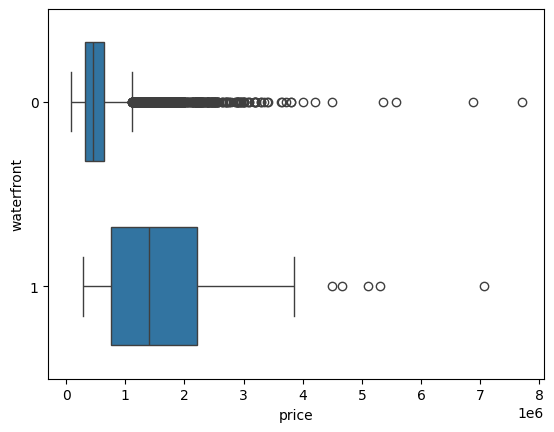

In [81]:
sns.boxplot(data=df, x='price', y='waterfront', gap=0.2, orient="h")

<Axes: xlabel='price', ylabel='yr_renovated'>

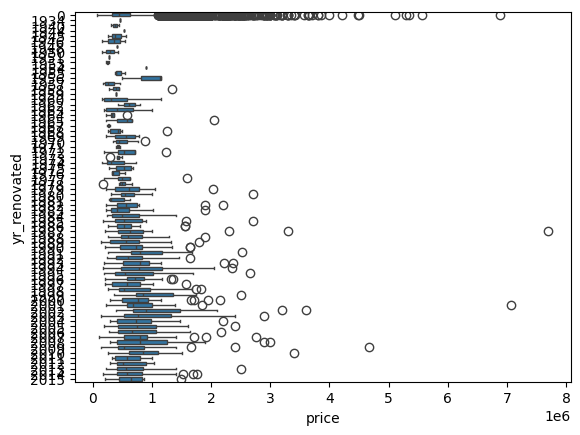

In [82]:
sns.boxplot(data=df, x='price', y='yr_renovated', gap=0.2, orient="h")

In [83]:
df[['price', 'waterfront']].corr()

,price,waterfront
price,1.000000,0.266438
waterfront,0.266438,1.000000


<Axes: xlabel='price', ylabel='view'>

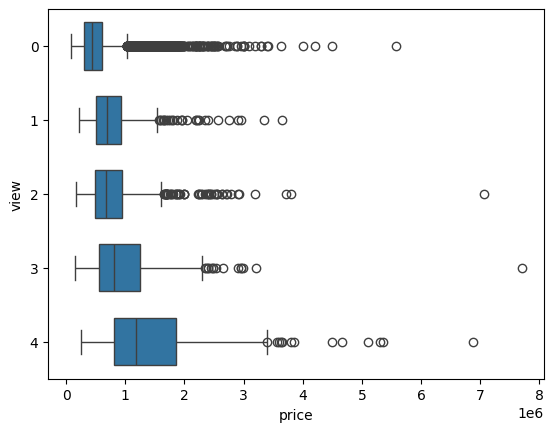

In [84]:
sns.boxplot(data=df, x='price', y='view', gap=0.2, orient="h")

In [85]:
# more times a house is viewed, the higher it sells for
df[['price', 'view']].corr()

,price,view
price,1.000000,0.397323
view,0.397323,1.000000


,price,sqft_living
price,1.00000,0.70194
sqft_living,0.70194,1.00000


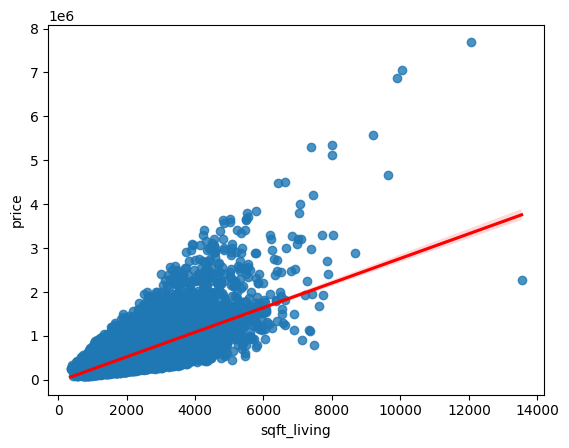

In [86]:
sns.regplot(data=df, x='sqft_living', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_living']].corr()

,price,sqft_above
price,1.000000,0.605405
sqft_above,0.605405,1.000000


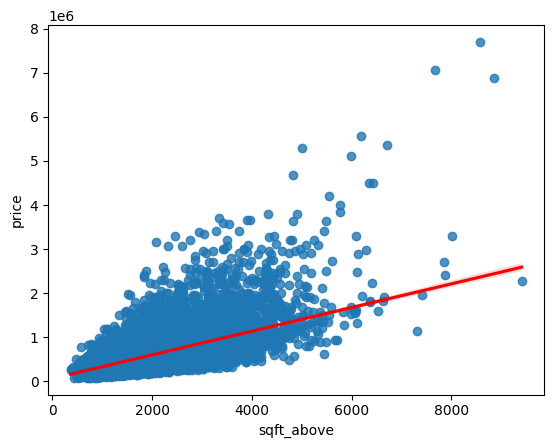

In [87]:
sns.regplot(data=df, x='sqft_above', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_above']].corr()

,price,sqft_basement
price,1.000000,0.323777
sqft_basement,0.323777,1.000000


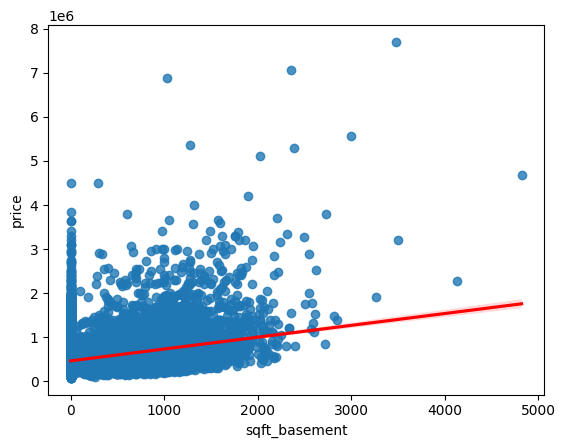

In [88]:
sns.regplot(data=df, x='sqft_basement', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_basement']].corr()

,price,yr_built
price,1.000000,0.053994
yr_built,0.053994,1.000000


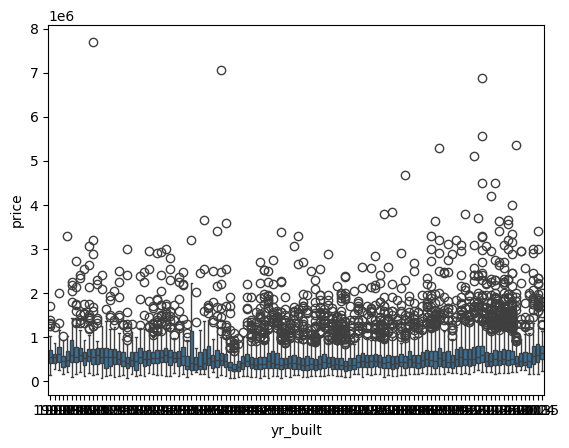

In [89]:
sns.boxplot(data=df, x='yr_built', y='price')
df[['price', 'yr_built']].corr()

In [90]:
# I will make new dataframe with yr built dummy columns to do testing
# yrbuilt does not seem to affect price as much
df_yrbuilt = df.copy()

In [91]:
df_yrbuilt = pd.get_dummies(df_yrbuilt, columns=['yr_built'], drop_first=True)

In [92]:
df_yrbuilt

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,yr_built_1901,yr_built_1902,yr_built_1903,yr_built_1904,yr_built_1905,yr_built_1906,yr_built_1907,yr_built_1908,yr_built_1909,yr_built_1910,yr_built_1911,yr_built_1912,yr_built_1913,yr_built_1914,yr_built_1915,yr_built_1916,yr_built_1917,yr_built_1918,yr_built_1919,yr_built_1920,yr_built_1921,yr_built_1922,yr_built_1923,yr_built_1924,yr_built_1925,yr_built_1926,yr_built_1927,yr_built_1928,yr_built_1929,yr_built_1930,yr_built_1931,yr_built_1932,yr_built_1933,yr_built_1934,yr_built_1935,yr_built_1936,yr_built_1937,yr_built_1938,yr_built_1939,yr_built_1940,yr_built_1941,yr_built_1942,yr_built_1943,yr_built_1944,yr_built_1945,yr_built_1946,yr_built_1947,yr_built_1948,yr_built_1949,yr_built_1950,yr_built_1951,yr_built_1952,yr_built_1953,yr_built_1954,yr_built_1955,yr_built_1956,yr_built_1957,yr_built_1958,yr_built_1959,yr_built_1960,yr_built_1961,yr_built_1962,yr_built_1963,yr_built_1964,yr_built_1965,yr_built_1966,yr_built_1967,yr_built_1968,yr_built_1969,yr_built_1970,yr_built_1971,yr_built_1972,yr_built_1973,yr_built_1974,yr_built_1975,yr_built_1976,yr_built_1977,yr_built_1978,yr_built_1979,yr_built_1980,yr_built_1981,yr_built_1982,yr_built_1983,yr_built_1984,yr_built_1985,yr_built_1986,yr_built_1987,yr_built_1988,yr_built_1989,yr_built_1990,yr_built_1991,yr_built_1992,yr_built_1993,yr_built_1994,yr_built_1995,yr_built_1996,yr_built_1997,yr_built_1998,yr_built_1999,yr_built_2000,yr_built_2001,yr_built_2002,yr_built_2003,yr_built_2004,yr_built_2005,yr_built_2006,yr_built_2007,yr_built_2008,yr_built_2009,yr_built_2010,yr_built_2011,yr_built_2012,yr_built_2013,yr_built_2014,yr_built_2015
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,0,98178,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1991,98125,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,0,98028,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Fa

,price,sqft_living15
price,1.00000,0.58528
sqft_living15,0.58528,1.00000


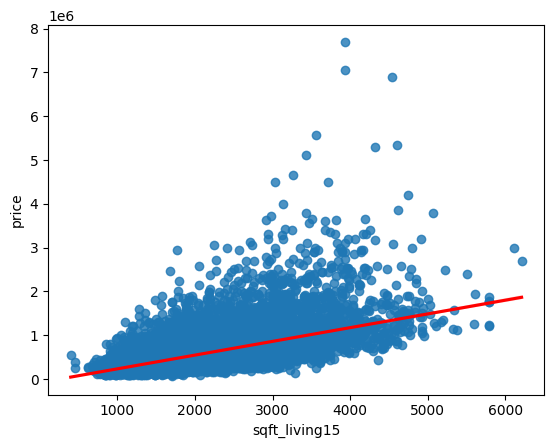

In [93]:
sns.regplot(data=df, x='sqft_living15', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_living15']].corr()

,price,sqft_lot15
price,1.00000,0.08284
sqft_lot15,0.08284,1.00000


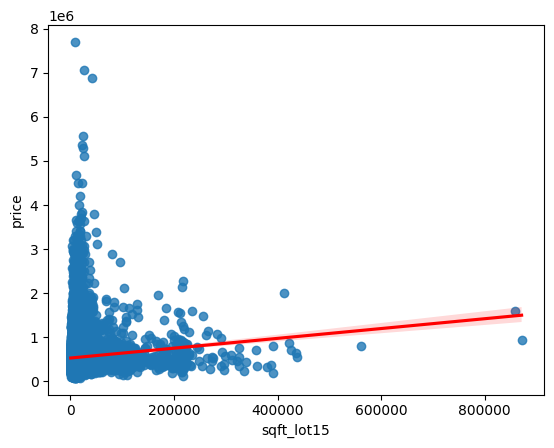

In [94]:
#this has almost no correlation
sns.regplot(data=df, x='sqft_lot15', y='price', line_kws=dict(color='red'))
df[['price', 'sqft_lot15']].corr()

# Conveinence Method for Evaluating Linear Regression Models

In [95]:
# Method for evaluating models

def evaluate_models(model):

  model.fit(X_train, y_train)

  # train r2
  train_r2 = round(model.score(X_train, y_train), 2)

  # test r2
  test_r2 = round(model.score(X_test, y_test), 2)

  # train MAE
  train_mae = round(mean_absolute_error(y_train, model.predict(X_train)) ,2)

  # test mae
  test_mae = round(mean_absolute_error(y_test, model.predict(X_test)), 2)

  # train rmse
  train_rmse = round(root_mean_squared_error(y_train, model.predict(X_train)), 2)

  # test rmse
  test_rmse = round(root_mean_squared_error(y_test, model.predict(X_test)), 2)

  output_df = pd.DataFrame({

      'train': [train_r2, train_mae, train_rmse],

      'test': [test_r2, test_mae, test_rmse]},

                           index=['R2', 'MAE', 'RMSE'])

  display(output_df)

  print(f'\nNumber of non-zero coefficients: {np.sum(model.coef_ != 0)}\n')

  print(f'Coefficients: {model.coef_}')

# Linear Regression 1


Below is the results of our data frames training linear regression models. Our best performing model was f_zipswatview, which had dummy coded columns for zipcode, waterfront, and view.

|   | train  | test  |
|---|---|---|
|R2|0.81|0.80|
|MAE|95391.41|94448.02|
|RMSE|159385.32|158960.82|


###Linear Regression with:

sqft_living

---

####Running Model

In [96]:
X = df[['sqft_living']]
y = df['price']

In [97]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [98]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

####Results

In [99]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in sqft_living, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.5
Test R2: 0.48
For every 1 increase in sqft_living, we would expect [282.99] increase in price


In [100]:
evaluate_models(lr)

,train,test
R2,0.50,0.48
MAE,174581.22,173263.50
RMSE,262762.30,257704.08



Number of non-zero coefficients: 1

Coefficients: [282.98868113]




---



###Linear Regression with:

sqft_living, sqft_living15, sqft_basement, sqft_above

---


####Running Model

In [101]:
X = df[['sqft_living', 'sqft_living15', 'sqft_basement', 'sqft_above']]
y = df['price']

In [102]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [103]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

####Results

In [104]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.51
Test R2: 0.49
For every 1 increase in Each Variable, we would expect [167.29  76.94 103.55  63.74] increase in price


In [105]:
evaluate_models(lr)

,train,test
R2,0.51,0.49
MAE,172895.06,171361.03
RMSE,260462.66,255867.33



Number of non-zero coefficients: 4

Coefficients: [167.29137313  76.9354498  103.55382197  63.73755117]


###Linear Regression with:

sqft_living, sqft_living15, sqft_basement, sqft_above, view, and waterfront

---


#### Running Model

In [106]:
X = df[['sqft_living', 'sqft_living15', 'sqft_basement', 'sqft_above', 'view', 'waterfront']]
y = df['price']

In [107]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [108]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

#### Results

In [109]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.56
Test R2: 0.54
For every 1 increase in Each Variable, we would expect [1.5243000e+02 5.6720000e+01 7.8900000e+01 7.3520000e+01 7.3565310e+04
 5.7560031e+05] increase in price


In [110]:
evaluate_models(lr)

,train,test
R2,0.56,0.54
MAE,165255.85,163966.52
RMSE,246118.99,241479.29



Number of non-zero coefficients: 6

Coefficients: [1.52426799e+02 5.67157450e+01 7.89028198e+01 7.35239787e+01
 7.35653107e+04 5.75600313e+05]


###Linear Regression with:

All columns except price

---



#### Running Model

In [111]:
X = df.drop(columns=['price'])
y = df['price']

In [112]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [113]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

#### Results

In [114]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.7
Test R2: 0.7
For every 1 increase in Each Variable, we would expect [-3.9224570e+04  4.2621400e+04  1.1172000e+02  9.0000000e-02
  6.2217800e+03  5.6818000e+05  5.3667560e+04  2.9578110e+04
  9.6784990e+04  7.1630000e+01  4.0100000e+01 -2.6494500e+03
  2.0730000e+01 -6.0859000e+02  5.9412164e+05 -2.2596721e+05
  2.3830000e+01 -3.6000000e-01  5.6744200e+03  3.4159980e+04
  3.7458940e+04  4.9220550e+04  5.1791180e+04  4.7487410e+04
  5.1861580e+04  4.4449350e+04  4.9239940e+04  4.9738420e+04
  4.2222180e+04  5.3242770e+04] increase in price


In [115]:
evaluate_models(lr)

,train,test
R2,0.70,0.70
MAE,126249.69,124751.00
RMSE,201330.49,196640.38



Number of non-zero coefficients: 30

Coefficients: [-3.92245663e+04  4.26214036e+04  1.11722997e+02  9.41798549e-02
  6.22178045e+03  5.68180001e+05  5.36675582e+04  2.95781066e+04
  9.67849877e+04  7.16259130e+01  4.00966872e+01 -2.64945059e+03
  2.07261771e+01 -6.08589727e+02  5.94121642e+05 -2.25967206e+05
  2.38317909e+01 -3.63128173e-01  5.67441629e+03  3.41599845e+04
  3.74589361e+04  4.92205462e+04  5.17911821e+04  4.74874127e+04
  5.18615781e+04  4.44493537e+04  4.92399448e+04  4.97384216e+04
  4.22221791e+04  5.32427704e+04]


###Linear Regression with original dataframe, using zipcode dummy columns

---


#### Running Model

In [116]:
X = df_zips.drop(columns=['price'])
y = df_zips['price']

In [117]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [118]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

#### Results

In [119]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.81
Test R2: 0.8
For every 1 increase in Each Variable, we would expect [np.float64(-28859.79), np.float64(24728.18), np.float64(113.27), np.float64(0.2), np.float64(-46702.61), np.float64(634522.43), np.float64(58202.71), np.float64(26849.27), np.float64(56665.43), np.float64(96.22), np.float64(17.05), np.float64(-662.2), np.float64(19.6), np.float64(178475.18), np.float64(-153457.53), np.float64(11.9), np.float64(-0.09), np.float64(5478.63), np.float64(25875.28), np.float64(31817.82), np.float64(43196.94), np.float64(51457.1), np.float64(48426.43), np.float64(49196.0), np.float64(43456.24), np.float64(42867.9), np.float64(48610.28), np.float64(47499.7), np.float64(57948.11), np.float64(39521.95), np.float64(-14963.57), np.float64(698025.06), np.float64(266101.87), np.float64(246451.85), np.float64(217469.18), np.float64(228310.81), np.float64(104959.73), np.float64(54101.57), np.float64(101337.34), np.float64(61119.32), np.float64(46586.25), np.float64(-37226.82), np.float

In [120]:
evaluate_models(lr)

,train,test
R2,0.81,0.80
MAE,95830.98,94844.35
RMSE,160103.41,159513.05



Number of non-zero coefficients: 98

Coefficients: [-2.88597901e+04  2.47281755e+04  1.13269775e+02  2.00181736e-01
 -4.67026129e+04  6.34522434e+05  5.82027116e+04  2.68492715e+04
  5.66654284e+04  9.62165748e+01  1.70531955e+01 -6.62200901e+02
  1.96034455e+01  1.78475178e+05 -1.53457529e+05  1.18962230e+01
 -9.22428754e-02  5.47862937e+03  2.58752768e+04  3.18178193e+04
  4.31969375e+04  5.14570998e+04  4.84264330e+04  4.91960042e+04
  4.34562392e+04  4.28679028e+04  4.86102815e+04  4.74996971e+04
  5.79481148e+04  3.95219488e+04 -1.49635650e+04  6.98025064e+05
  2.66101866e+05  2.46451854e+05  2.17469184e+05  2.28310809e+05
  1.04959728e+05  5.41015676e+04  1.01337341e+05  6.11193230e+04
  4.65862468e+04 -3.72268235e+04  1.73546299e+05  1.66571281e+05
  5.06661538e+04  2.12872538e+05  1.29470508e+04  9.90428707e+03
 -1.21494448e+03  3.18146730e+05  1.43759439e+05  5.87289599e+04
  1.35862157e+06  4.80295479e+05  1.95499941e+04  1.42224022e+05
  1.90210778e+05  1.66005374e+05  3.39

###Linear Regression with dummy columns in zipcode, waterfront, and view
---


#### Running Model

In [121]:
X = df_zipswatview.drop(columns=['price'])
y = df_zipswatview['price']

In [122]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [123]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

#### Results

In [124]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.81
Test R2: 0.8
For every 1 increase in Each Variable, we would expect [np.float64(-28757.36), np.float64(25125.83), np.float64(112.78), np.float64(0.2), np.float64(-46482.88), np.float64(26324.84), np.float64(56791.61), np.float64(96.09), np.float64(16.69), np.float64(-688.78), np.float64(18.76), np.float64(182199.25), np.float64(-150627.02), np.float64(12.62), np.float64(-0.1), np.float64(4706.19), np.float64(25669.0), np.float64(31193.28), np.float64(43246.33), np.float64(51014.08), np.float64(48545.76), np.float64(49186.81), np.float64(43167.21), np.float64(42586.44), np.float64(48904.88), np.float64(47189.22), np.float64(58250.39), np.float64(39170.13), np.float64(-12791.3), np.float64(694335.12), np.float64(262390.72), np.float64(244507.2), np.float64(215504.16), np.float64(226958.68), np.float64(104875.58), np.float64(51612.68), np.float64(100770.41), np.float64(58605.98), np.float64(51008.82), np.float64(-36920.92), np.float64(174521.29), np.float64(165711.15), np.f

In [125]:
evaluate_models(lr)

,train,test
R2,0.81,0.80
MAE,95391.41,94448.02
RMSE,159385.32,158960.82



Number of non-zero coefficients: 101

Coefficients: [-2.87573632e+04  2.51258280e+04  1.12781327e+02  2.03384756e-01
 -4.64828809e+04  2.63248403e+04  5.67916088e+04  9.60893208e+01
  1.66920020e+01 -6.88780734e+02  1.87592053e+01  1.82199246e+05
 -1.50627019e+05  1.26227309e+01 -9.63642674e-02  4.70618853e+03
  2.56689996e+04  3.11932785e+04  4.32463333e+04  5.10140817e+04
  4.85457559e+04  4.91868099e+04  4.31672127e+04  4.25864371e+04
  4.89048792e+04  4.71892158e+04  5.82503871e+04  3.91701274e+04
 -1.27913009e+04  6.94335122e+05  2.62390719e+05  2.44507204e+05
  2.15504164e+05  2.26958680e+05  1.04875579e+05  5.16126806e+04
  1.00770407e+05  5.86059816e+04  5.10088216e+04 -3.69209210e+04
  1.74521286e+05  1.65711146e+05  4.76887590e+04  2.11265634e+05
  1.24813487e+04  8.78611977e+03 -5.92114707e+02  3.17606443e+05
  1.41556226e+05  5.71880381e+04  1.35487356e+06  4.80796225e+05
  1.89341013e+04  1.42030590e+05  1.88183930e+05  1.63215037e+05
  3.36695355e+04  7.90841390e+04  2.6

###Linear Regression with all columns dataframe and yrbuilt dummy columns
---


#### Running Model

In [126]:
X = df_yrbuilt.drop(columns=['price'])
y = df_yrbuilt['price']

In [127]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [128]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

####Results

In [129]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.71
Test R2: 0.7
For every 1 increase in Each Variable, we would expect [np.float64(-34840.44), np.float64(44013.02), np.float64(108.62), np.float64(0.1), np.float64(-12720.77), np.float64(577017.35), np.float64(53367.7), np.float64(31441.03), np.float64(101812.54), np.float64(67.91), np.float64(40.7), np.float64(16.75), np.float64(-757.91), np.float64(579741.41), np.float64(-205052.29), np.float64(25.59), np.float64(-0.26), np.float64(4313.01), np.float64(32898.97), np.float64(36167.17), np.float64(46764.6), np.float64(52486.36), np.float64(47454.26), np.float64(50646.84), np.float64(43028.56), np.float64(48793.47), np.float64(48979.27), np.float64(41314.96), np.float64(53470.99), np.float64(-41462.62), np.float64(-11237.45), np.float64(-80828.92), np.float64(20950.42), np.float64(52367.87), np.float64(20678.81), np.float64(-10842.26), np.float64(-42380.2), np.float64(-4094.74), np.float64(24509.05), np.float64(-36977.55), np.float64(-38291.78), np.float64(-42162.69), np.fl

In [130]:
evaluate_models(lr)

,train,test
R2,0.71,0.70
MAE,124443.48,123561.67
RMSE,198117.17,194219.83



Number of non-zero coefficients: 144

Coefficients: [-3.48404429e+04  4.40130196e+04  1.08617904e+02  9.80276051e-02
 -1.27207653e+04  5.77017348e+05  5.33676954e+04  3.14410302e+04
  1.01812537e+05  6.79146077e+01  4.07032954e+01  1.67498330e+01
 -7.57909898e+02  5.79741409e+05 -2.05052291e+05  2.55892725e+01
 -2.62931105e-01  4.31301229e+03  3.28989689e+04  3.61671732e+04
  4.67645996e+04  5.24863584e+04  4.74542589e+04  5.06468363e+04
  4.30285645e+04  4.87934743e+04  4.89792654e+04  4.13149556e+04
  5.34709944e+04 -4.14626204e+04 -1.12374459e+04 -8.08289217e+04
  2.09504245e+04  5.23678746e+04  2.06788123e+04 -1.08422606e+04
 -4.23802021e+04 -4.09474103e+03  2.45090492e+04 -3.69775471e+04
 -3.82917834e+04 -4.21626893e+04 -2.55755401e+04 -3.52164682e+04
 -5.08617001e+04 -5.34023631e+04 -4.93669947e+04 -5.94292854e+04
 -4.24681205e+04 -4.11453049e+04 -2.15169005e+04  6.88060125e+03
 -4.39818396e+04 -3.97319778e+04 -3.55974942e+04 -3.51146166e+04
 -5.68498328e+04 -9.26823857e+04 -7.7

###Linear Regression with dataframe, using zipcode, waterfront, view dummy columns. And Renovated Column.
---

#### Running Model

In [131]:
X = df_zipswatview_ren.drop(columns=['price', 'yr_renovated'])
y = df_zipswatview_ren['price']

In [132]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [133]:
# make instance of model
lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

####Results

In [134]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in Each Variable, we would expect {list(lr.coef_.round(2))} increase in price')

Train R2: 0.81
Test R2: 0.8
For every 1 increase in Each Variable, we would expect [np.float64(-28759.39), np.float64(25153.7), np.float64(112.78), np.float64(0.2), np.float64(-46473.05), np.float64(26296.97), np.float64(56801.6), np.float64(96.08), np.float64(16.7), np.float64(-690.0), np.float64(182224.56), np.float64(-150566.85), np.float64(12.61), np.float64(-0.1), np.float64(4704.43), np.float64(25670.31), np.float64(31191.38), np.float64(43249.59), np.float64(51006.57), np.float64(48544.68), np.float64(49180.68), np.float64(43163.51), np.float64(42577.21), np.float64(48894.82), np.float64(47181.6), np.float64(58240.15), np.float64(39177.28), np.float64(-12793.71), np.float64(694346.5), np.float64(262378.65), np.float64(244500.31), np.float64(215493.36), np.float64(226947.08), np.float64(104879.3), np.float64(51589.05), np.float64(100746.66), np.float64(58588.85), np.float64(51014.42), np.float64(-36912.89), np.float64(174514.66), np.float64(165692.87), np.float64(47667.27), np.fl

In [135]:
evaluate_models(lr)

,train,test
R2,0.81,0.80
MAE,95395.26,94450.07
RMSE,159388.19,158964.90



Number of non-zero coefficients: 101

Coefficients: [-2.87593920e+04  2.51536968e+04  1.12778736e+02  2.03335116e-01
 -4.64730546e+04  2.62969725e+04  5.68015957e+04  9.60815342e+01
  1.66971978e+01 -6.90003999e+02  1.82224558e+05 -1.50566853e+05
  1.26092041e+01 -9.63135753e-02  4.70442716e+03  2.56703054e+04
  3.11913790e+04  4.32495902e+04  5.10065689e+04  4.85446810e+04
  4.91806838e+04  4.31635127e+04  4.25772083e+04  4.88948244e+04
  4.71815974e+04  5.82401459e+04  3.91772839e+04 -1.27937081e+04
  6.94346499e+05  2.62378650e+05  2.44500310e+05  2.15493356e+05
  2.26947083e+05  1.04879303e+05  5.15890501e+04  1.00746656e+05
  5.85888455e+04  5.10144158e+04 -3.69128896e+04  1.74514663e+05
  1.65692871e+05  4.76672684e+04  2.11235616e+05  1.24752203e+04
  8.78092438e+03 -5.88709846e+02  3.17604339e+05  1.41534734e+05
  5.71856335e+04  1.35488428e+06  4.80807974e+05  1.89467063e+04
  1.41999527e+05  1.88167952e+05  1.63199055e+05  3.36594364e+04
  7.90862876e+04  2.68015051e+04  6.8

# Linear Regression 2

So far, our best performace came from df_zipswatview.
We were able to get the below results. Our R² seems to be quite high, and we have a good fit, but our MAE is quite high for predicting housing prices. We will try to engineer some more features and get better numbers with linear regression.  

So far, zipcode has been the number 1 indicator of housing prices. This tells us that location is probably the number 1 factor in how much a house costs. We will attempt to explore the data, and engineer some features to better train our model.

|   | train  | test  |
|---|---|---|
|R2|0.81|0.80|
|MAE|95391.41|94448.02|
|RMSE|159385.32|158960.82|

In [136]:
# Create new dataframe
df2 = df_zipswatview

In [137]:
#check dataframe
df2.head(1)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1,view_1,view_2,view_3,view_4
0,221900.0,3,1.0,1180,5650,1.0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False


#### Map out data

<Axes: xlabel='long', ylabel='lat'>

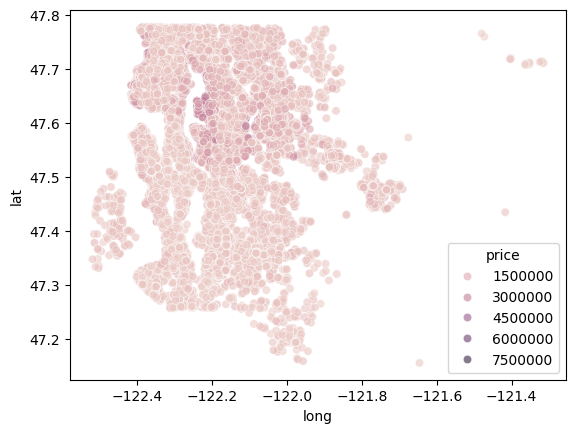

In [138]:
# Scatter plot of Lat and Long and colorized price
sns.scatterplot(
    data=df2,
    x='long',
    y='lat',
    alpha=0.6,
    hue='price'
)

In [139]:
# pull in zip code map files
map_file_path = '/content/drive/MyDrive/_Intro to data science/Project1/tl_2020_us_zcta520.zip'
zips = gpd.read_file(map_file_path)

#rename zipcode column
zips = zips.rename(columns={"ZCTA5CE20": "zip"})

In [140]:
#pull in data
dfmap = pd.read_csv(file_path)

In [141]:
#make sure the zips are strings in the map file
zips["zip"] = zips["zip"].astype(str).str.strip()

#get target zips from our dataset
target_zips = dfmap['zipcode'].astype(str).tolist()

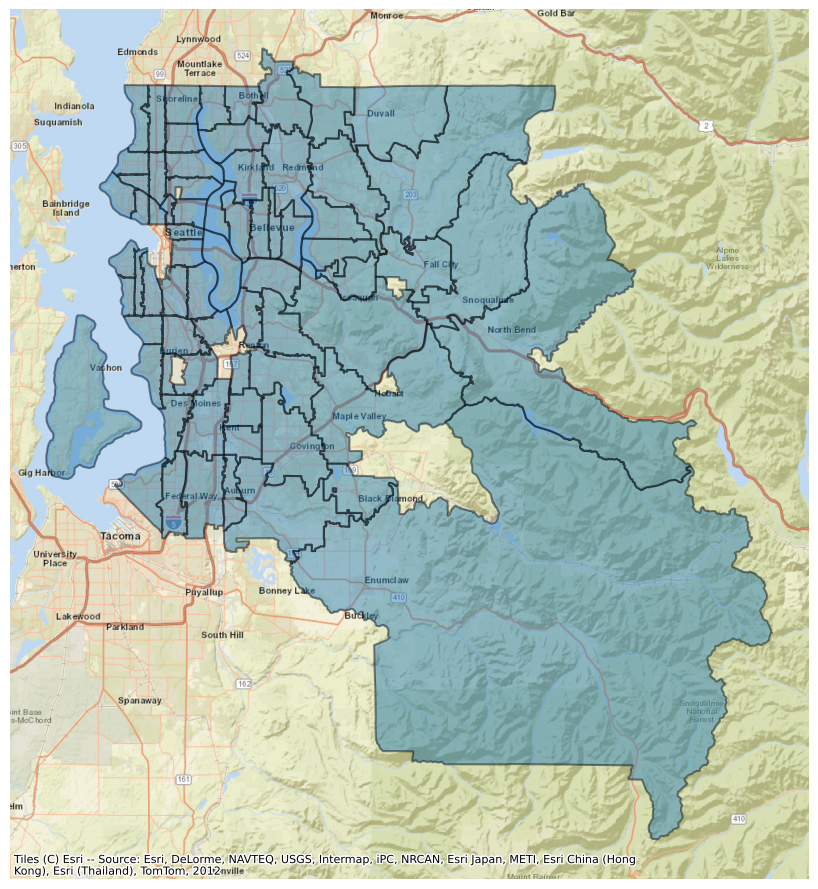

In [142]:
gdf = zips[zips["zip"].isin(target_zips)]
gdf_3857 = gdf.to_crs(epsg=3857)
ax = gdf_3857.plot(
    #column="price",
    legend=True,
    alpha=0.45,
    edgecolor="black",
    linewidth=1.5,
    figsize=(9, 9),
)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldStreetMap)
ax.set_axis_off()
plt.tight_layout()
plt.show()

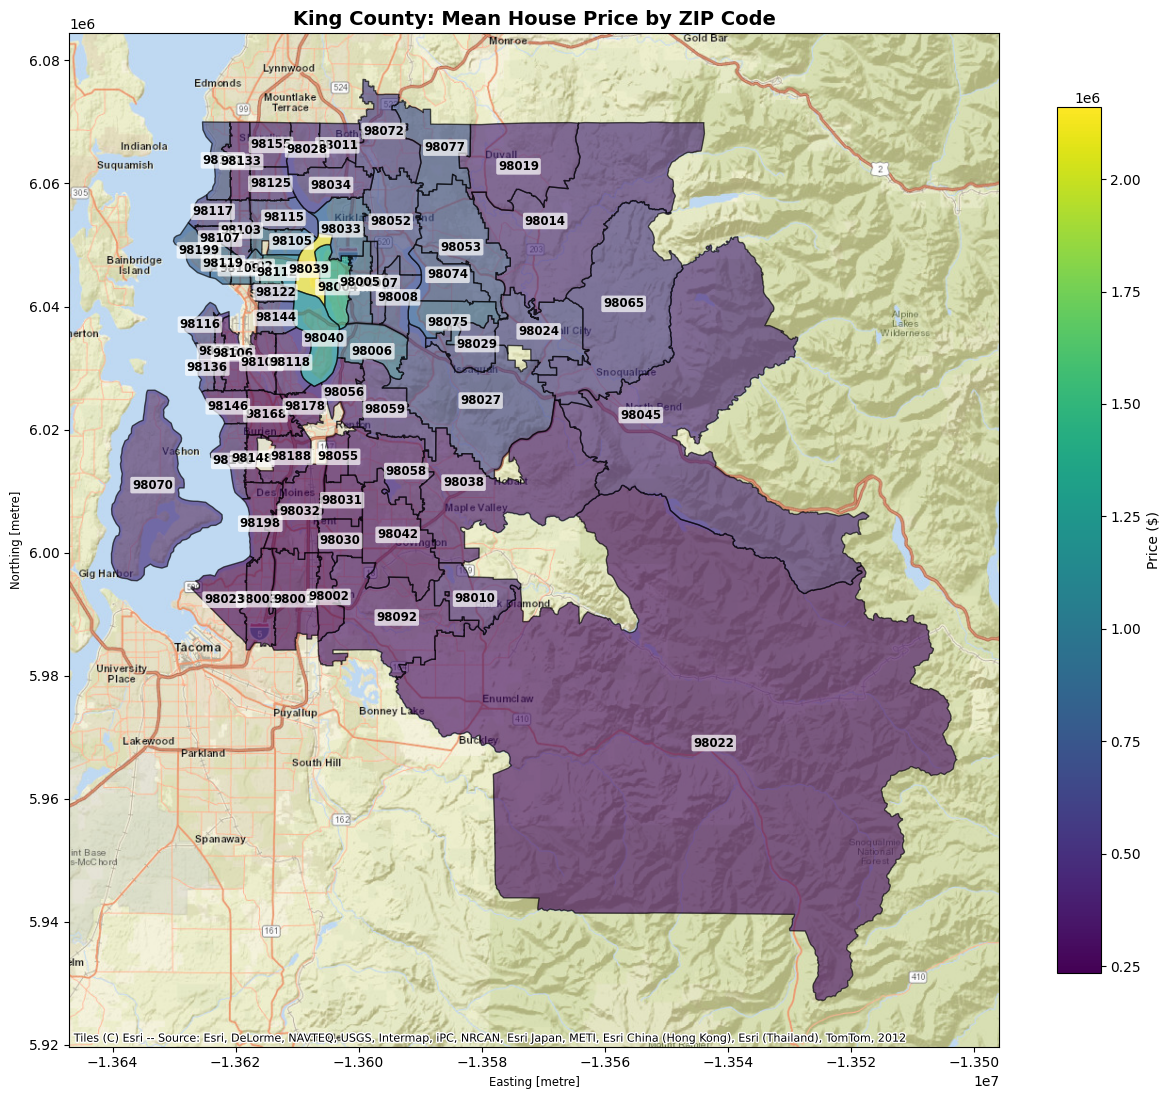

In [143]:


# Make duplicate dataframe, and ensure price is a string
dfmap2 = dfmap.copy()
dfmap["zipcode"] = dfmap["zipcode"].dropna().astype(str).str.strip()
dfmap["price"] = pd.to_numeric(
    dfmap["price"].astype(str),
    errors="coerce",
)

# Get the mean price by zipcode
price_by_zip = dfmap.groupby("zipcode", as_index=False)["price"].mean()

# Filter The shapes by zipcode
target_zips = price_by_zip["zipcode"].unique().tolist()
gdf = zips[zips["zip"].isin(target_zips)].merge(
    price_by_zip,
    left_on="zip",
    right_on="zipcode",
    how="left",
)

# Drop ZIPs without a valid price so they don't plot blank/weirdly
gdf = gdf.dropna(subset=["price"])

# Use EPSG:3857 and plot on map
gdf_3857 = gdf.to_crs(epsg=3857)
ax = gdf_3857.plot(
    #title='alsdfkj',
    column="price",
    cmap='viridis',
    #cmap="YlOrRd",
    legend=True,
    legend_kwds={"label": "Price ($)", "shrink": 0.75},
    alpha=0.65,
    edgecolor="black",
    linewidth=1.0,
    figsize=(15, 15),
)

# Place zip label inside each shape
for _, row in gdf_3857.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(
        text=row["zip"],
        xy=(pt.x, pt.y),
        ha="center",
        va="center",
        fontsize=8.5,
        fontweight="bold",
        color="black",
        bbox=dict(boxstyle="round,pad=0.15", facecolor="white", alpha=0.7, edgecolor="none"),
    )

    ax.set_title(
    "King County: Mean House Price by ZIP Code",
    fontsize=14,
    fontweight="bold",
)

ctx.add_basemap(ax, source=ctx.providers.Esri.WorldStreetMap)
plt.show()

#### Feature Creation

After plotting a heatmap of mean prices by zipcode. We can see that the general trend is that 98039 which corresponds to the Medina neighborhood area is the most expensive, and then in general, the further away from that zipcode you get. The cheaper the house becomes.

The biggest business in that area is the golf course at 8000 NE 16th St, Medina, WA 98039, which has a lat/long of 47.6251882,-122.2328743

We will try and use this to engineer a feature around this.


##### Engineer distance to golf course

In [144]:
# The lattitude and Longitude of the Medina Golf Course
golf_lat = 47.6251882
golf_long = -122.2328743

In [145]:
# Calculating the distance of the first house in our dataset
# I am using kilometers instead of miles to as this might be a better unit of measure to use as it is smaller

golf_coordinates = (golf_lat, golf_long)
first_house_coordinates = (df2.loc[0, 'lat'], df2.loc[0, 'long'])

distance = geodesic(golf_coordinates, first_house_coordinates).kilometers
distance

12.802783817825702

In [146]:
distances = []

for lat, lg in zip(df2['lat'], df2['long']):
  distance = geodesic(golf_coordinates, (lat, lg)).kilometers
  distances.append(distance)

In [147]:
df2['dist_to_golf_Medina'] = distances

In [148]:
df2.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,lat,long,sqft_living15,sqft_lot15,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12,year_2015,zipcode_98002,zipcode_98003,zipcode_98004,zipcode_98005,zipcode_98006,zipcode_98007,zipcode_98008,zipcode_98010,zipcode_98011,zipcode_98014,zipcode_98019,zipcode_98022,zipcode_98023,zipcode_98024,zipcode_98027,zipcode_98028,zipcode_98029,zipcode_98030,zipcode_98031,zipcode_98032,zipcode_98033,zipcode_98034,zipcode_98038,zipcode_98039,zipcode_98040,zipcode_98042,zipcode_98045,zipcode_98052,zipcode_98053,zipcode_98055,zipcode_98056,zipcode_98058,zipcode_98059,zipcode_98065,zipcode_98070,zipcode_98072,zipcode_98074,zipcode_98075,zipcode_98077,zipcode_98092,zipcode_98102,zipcode_98103,zipcode_98105,zipcode_98106,zipcode_98107,zipcode_98108,zipcode_98109,zipcode_98112,zipcode_98115,zipcode_98116,zipcode_98117,zipcode_98118,zipcode_98119,zipcode_98122,zipcode_98125,zipcode_98126,zipcode_98133,zipcode_98136,zipcode_98144,zipcode_98146,zipcode_98148,zipcode_98155,zipcode_98166,zipcode_98168,zipcode_98177,zipcode_98178,zipcode_98188,zipcode_98198,zipcode_98199,waterfront_1,view_1,view_2,view_3,view_4,dist_to_golf_Medina
0,221900.0,3,1.00,1180,5650,1.0,3,7,1180,0,1955,0,47.5112,-122.257,1340,5650,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,12.802784
1,538000.0,3,2.25,2570,7242,2.0,3,7,2170,400,1951,1991,47.7210,-122.319,1690,7639,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,12.462397
2,180000.0,2,1.00,770,10000,1.0,3,6,770,0,1933,0,47.7379,-122.233,2720,8062,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,12.531766
3,604000.0,4,3.00,1960,5000,1.0,5,7,1050,910,1965,0,47.5208,-122.393,1360,5000,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,16.728670
4,510000.0,3,2.00,1680,8080,1.0,3,8,1680,0,1987,0,47.6168,-122.045,1800,7503,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,Fal

##### Engineer sqft per rooms


In [149]:
sqft_per_rooms = (df2['sqft_above'] + df2['sqft_basement']) / (df2['bathrooms'] + df2['bedrooms'])

In [150]:
df2['sqft_per_rooms'] = sqft_per_rooms

##### Engineer bathrooms per sqft

In [151]:
df2['baths_per_sqft'] = round(df2['bathrooms'] / (df2['sqft_above'] + df2['sqft_basement']), 5)

##### Engineer bedrooms per sqft

In [152]:
df2['beds_per_sqft'] = round(df2['bedrooms'] / (df2['sqft_above'] + df2['sqft_basement']), 5)

##### Engineer indoor outdoor ratio



In [153]:
df2['in_out_ratio'] = (df2['sqft_above'] + df2['sqft_basement']) / df2['sqft_lot']

##### Dummy code floors

In [154]:
df2 = pd.get_dummies(df2, columns=['floors'], drop_first=True)

##### Engineer sqft_living to sqft_living15 ratio

In [155]:
df2['sqft_liv_15_ratio'] = df2['sqft_living']  / df2['sqft_living15']

#### Run Linear Regression

In [156]:
X = df2.drop(columns=['price', 'lat', 'long', 'yr_built'])

y = df2['price']

In [157]:
X_train, X_test, y_train, y_test = train_test_split(

X, y, test_size=0.25, random_state=42)

In [158]:
# make instance of model

lr = LinearRegression()

# fit our model
lr.fit(X_train, y_train)

LinearRegression()

In [159]:
print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')
print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')
print(f'For every 1 increase in sqft_living, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.84
Test R2: 0.82
For every 1 increase in sqft_living, we would expect [-1.24611630e+05  3.34158700e+04  2.36540000e+02  1.60000000e-01
  3.15858500e+04  5.51025200e+04  1.40670000e+02  9.56100000e+01
  2.98100000e+01 -1.89100000e+01 -1.90000000e-01  1.68615000e+03
  2.52738100e+04  3.14593100e+04  4.56687600e+04  5.55651000e+04
  5.23047500e+04  5.51081100e+04  4.73856800e+04  5.04996600e+04
  5.42212200e+04  5.48354100e+04  6.45090900e+04  2.55863500e+04
 -9.15588000e+03  4.64308510e+05  5.87813300e+04  5.21224200e+04
  2.46817200e+04  4.70399200e+04  6.92584400e+04 -4.20276900e+04
  4.91230200e+04  6.87880000e+02  1.22038780e+05 -1.65014000e+04
  7.06246800e+04  3.10057500e+04 -4.43393400e+04  8.49108100e+04
 -4.43400500e+04 -7.34671600e+04 -5.90946200e+04  1.31182350e+05
 -3.80734000e+03  1.18275900e+04  1.05680795e+06  2.69515610e+05
 -4.34841400e+04  1.26709950e+05  3.31095600e+04  4.19333500e+04
 -8.25605400e+04 -8.83484400e+04 -8.65788600e+04 -7.71096000e+04
  3.7524

In [160]:
evaluate_models(lr)

,train,test
R2,0.84,0.82
MAE,89610.76,89032.67
RMSE,150128.18,150269.75



Number of non-zero coefficients: 108

Coefficients: [-1.24611625e+05  3.34158746e+04  2.36535887e+02  1.55629221e-01
  3.15858461e+04  5.51025217e+04  1.40673749e+02  9.56100430e+01
  2.98067171e+01 -1.89143278e+01 -1.93143250e-01  1.68615406e+03
  2.52738105e+04  3.14593058e+04  4.56687646e+04  5.55650953e+04
  5.23047463e+04  5.51081058e+04  4.73856785e+04  5.04996568e+04
  5.42212203e+04  5.48354127e+04  6.45090938e+04  2.55863495e+04
 -9.15587807e+03  4.64308513e+05  5.87813251e+04  5.21224164e+04
  2.46817162e+04  4.70399179e+04  6.92584433e+04 -4.20276864e+04
  4.91230208e+04  6.87876073e+02  1.22038783e+05 -1.65013989e+04
  7.06246841e+04  3.10057501e+04 -4.43393419e+04  8.49108079e+04
 -4.43400549e+04 -7.34671554e+04 -5.90946244e+04  1.31182351e+05
 -3.80733828e+03  1.18275894e+04  1.05680795e+06  2.69515609e+05
 -4.34841447e+04  1.26709946e+05  3.31095556e+04  4.19333527e+04
 -8.25605384e+04 -8.83484365e+04 -8.65788616e+04 -7.71096040e+04
  3.75243363e+04 -1.47441616e+04 -8.7

### Results

In [161]:
lr.fit(X_train, y_train)

print(f'Train R2: {round(lr.score(X_train, y_train), 2)}')

print(f'Test R2: {round(lr.score(X_test, y_test) , 2)}')

print(f'For every 1 increase in sqft_living, we would expect {lr.coef_.round(2)} increase in price')

Train R2: 0.84
Test R2: 0.82
For every 1 increase in sqft_living, we would expect [-1.24611630e+05  3.34158700e+04  2.36540000e+02  1.60000000e-01
  3.15858500e+04  5.51025200e+04  1.40670000e+02  9.56100000e+01
  2.98100000e+01 -1.89100000e+01 -1.90000000e-01  1.68615000e+03
  2.52738100e+04  3.14593100e+04  4.56687600e+04  5.55651000e+04
  5.23047500e+04  5.51081100e+04  4.73856800e+04  5.04996600e+04
  5.42212200e+04  5.48354100e+04  6.45090900e+04  2.55863500e+04
 -9.15588000e+03  4.64308510e+05  5.87813300e+04  5.21224200e+04
  2.46817200e+04  4.70399200e+04  6.92584400e+04 -4.20276900e+04
  4.91230200e+04  6.87880000e+02  1.22038780e+05 -1.65014000e+04
  7.06246800e+04  3.10057500e+04 -4.43393400e+04  8.49108100e+04
 -4.43400500e+04 -7.34671600e+04 -5.90946200e+04  1.31182350e+05
 -3.80734000e+03  1.18275900e+04  1.05680795e+06  2.69515610e+05
 -4.34841400e+04  1.26709950e+05  3.31095600e+04  4.19333500e+04
 -8.25605400e+04 -8.83484400e+04 -8.65788600e+04 -7.71096000e+04
  3.7524

In [162]:
evaluate_models(lr)

,train,test
R2,0.84,0.82
MAE,89610.76,89032.67
RMSE,150128.18,150269.75



Number of non-zero coefficients: 108

Coefficients: [-1.24611625e+05  3.34158746e+04  2.36535887e+02  1.55629221e-01
  3.15858461e+04  5.51025217e+04  1.40673749e+02  9.56100430e+01
  2.98067171e+01 -1.89143278e+01 -1.93143250e-01  1.68615406e+03
  2.52738105e+04  3.14593058e+04  4.56687646e+04  5.55650953e+04
  5.23047463e+04  5.51081058e+04  4.73856785e+04  5.04996568e+04
  5.42212203e+04  5.48354127e+04  6.45090938e+04  2.55863495e+04
 -9.15587807e+03  4.64308513e+05  5.87813251e+04  5.21224164e+04
  2.46817162e+04  4.70399179e+04  6.92584433e+04 -4.20276864e+04
  4.91230208e+04  6.87876073e+02  1.22038783e+05 -1.65013989e+04
  7.06246841e+04  3.10057501e+04 -4.43393419e+04  8.49108079e+04
 -4.43400549e+04 -7.34671554e+04 -5.90946244e+04  1.31182351e+05
 -3.80733828e+03  1.18275894e+04  1.05680795e+06  2.69515609e+05
 -4.34841447e+04  1.26709946e+05  3.31095556e+04  4.19333527e+04
 -8.25605384e+04 -8.83484365e+04 -8.65788616e+04 -7.71096040e+04
  3.75243363e+04 -1.47441616e+04 -8.7

# Ridge Regression



We will try ridge regression using the original dataframe that gave us the best results

In [163]:
ridge = Ridge()
evaluate_models(ridge)

,train,test
R2,0.83,0.82
MAE,90733.72,90473.09
RMSE,151671.19,152104.68



Number of non-zero coefficients: 108

Coefficients: [-1.00932084e+05 -5.48003326e+04  2.80458646e+02  1.59559091e-01
  3.10453763e+04  5.59680410e+04  1.66332432e+02  1.14128037e+02
  3.09979659e+01 -3.93248552e+01 -1.78843515e-01  1.37828588e+03
  2.39666403e+04  3.00627482e+04  4.21761547e+04  5.14092444e+04
  4.89381825e+04  5.09624522e+04  4.44817114e+04  4.58954554e+04
  4.95697713e+04  5.04750623e+04  6.20692339e+04  2.33236106e+04
 -2.09986637e+04  4.13634878e+05  4.18150579e+03  1.11785627e+04
 -2.13187766e+04  2.21349235e+03  6.04983258e+04 -8.03319635e+04
  3.23283490e+04 -2.52724942e+04  1.27132419e+05 -2.08238905e+04
  5.40518570e+04  1.72874826e+02 -8.28145385e+04  5.37413125e+04
 -6.36290699e+04 -9.73382408e+04 -7.25566031e+04  8.75320029e+04
 -4.19188415e+04 -5.43826251e+03  9.90003265e+05  2.21831710e+05
 -5.65690190e+04  1.22525459e+05 -1.03738659e+04  7.38880144e+03
 -1.12257749e+05 -1.21143000e+05 -1.15170147e+05 -1.10876407e+05
  2.04404452e+04 -3.21372354e+04 -4.4

# Lasso Regression


In [165]:


ss = StandardScaler()

ss.fit(X_train)

X_train_scaled = pd.DataFrame(ss.transform(X_train), columns=X_train.columns)

X_test_scaled = pd.DataFrame(ss.transform(X_test), columns=X_test.columns)

lasso = Lasso(alpha=25000, max_iter=25000)

lasso.fit(X_train_scaled, y_train)

evaluate_models(lasso)



,train,test
R2,0.65,0.64
MAE,136546.77,134917.05
RMSE,218951.72,214810.78



Number of non-zero coefficients: 9

Coefficients: [-0.00000000e+00 -0.00000000e+00  1.99654409e+02  3.22090387e-01
  0.00000000e+00  2.36561318e+04  1.60539509e+01 -0.00000000e+00
  7.11070771e+01  5.49985426e+01  4.71571370e-02  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00  0.00000000e+00 -0.00000000e+00
  0.00000000e+00 -0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00 -0.00000000e+00 -0.00000000e+00  0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00  0.00000000e+00
 -0.00000000e+00 -0.00000000e+00  0.00000000e+00  0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.000

# Decision Tree Regression
We will try to use our best dataset with a decision tree regressor

In [166]:
from sklearn.tree import DecisionTreeRegressor

# make instance of the model
dtr = DecisionTreeRegressor(max_depth=9, random_state=23)

# fit on the training data
dtr.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=9, random_state=23)

In [167]:
print(f'Train Accuracy: {dtr.score(X_train, y_train)}')
print(f'Test Accuracy: {dtr.score(X_test, y_test)}')

Train Accuracy: 0.8891801459236838
Test Accuracy: 0.7868754712837859


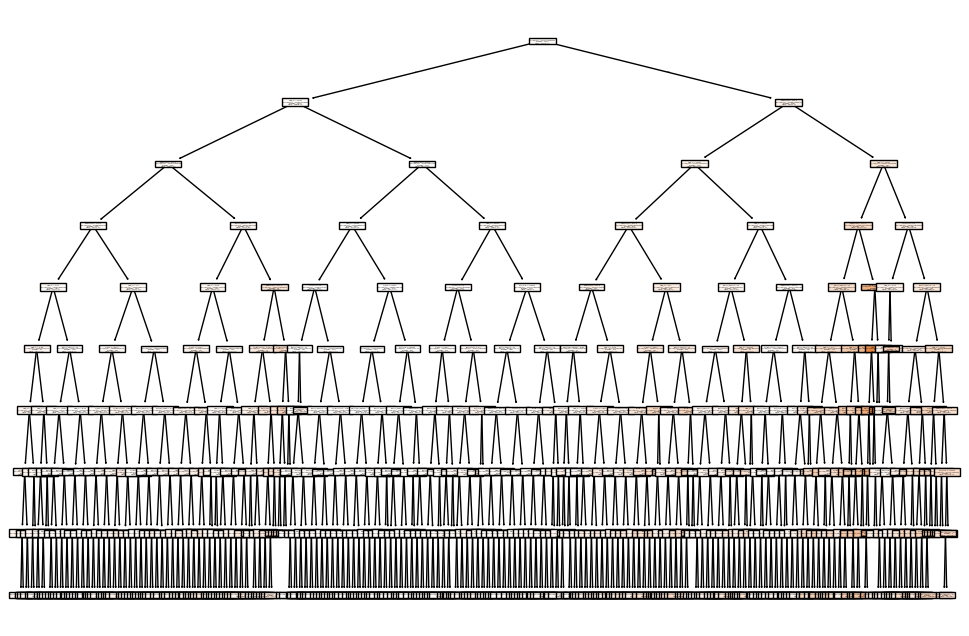

In [168]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plot_tree(dtr, feature_names=df2.columns, filled=True);

# RandomForestRegressor

In [184]:
from sklearn.ensemble import RandomForestRegressor

# make instance of our model
rf = RandomForestRegressor(max_depth=20)

# fit our model
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=20)

In [185]:
print(f'Train Accuracy: {round(rf.score(X_train, y_train), 2)}')
print(f'Test Accuracy: {round(rf.score(X_test, y_test), 2)}')

Train Accuracy: 0.98
Test Accuracy: 0.87


# Conclusion

In this project, I built and evaluated several regression models to predict housing prices in King County.

Initial tests with linear regression gave me an r2 of about 0.5. Size is the strongest predictor, but only seems to explain about 50% of the variance.

After running linear regression  on all of the features, plus dummy coded zip codes we saw an increase in the r2 to about 0.81. This is due to the zip codes having been treated by the model as a numerical data type, when in fact they are categorical data types, and zip code dictates house price greatly.

I explored the data a little more and mapped out prices by zip code. I saw that distance from the 98039 zip code directly correlates to price, which is shown in the image below. So after choosing a point in that zip code, and measuring distance, as well as engineering some more features, I was able to attain a test R2 of 0.84

I attempted to use Ridge, Lasso, DecisionTree, and RandomForest Regression as well.

Ridge - Ridge regression did not have an improvement in our R2. We did not see overfitting with linear regression, so punishing coefficients did not show improvement.

Lasso - Lasso regression did not produce good results. In order to get it to converge, I had to increase the iterations and the alpha value. Better feature selection and engineering could help this, as well as access to a better CPU.

DecisionTree - The decision tree showed promise and may be a good fit, with more feature engineering. With a depth of 9, I obtained an accuracy of 78.

RandomForest - This model also showed promise. With a max depth of 20, I obtained a test accuracy of 87, but saw overfitting. With more work, this may be able to be made more acccurate.

Key Takeaways
* Importance choosing Features: Converting categorical fields like zipcode into dummy values, I saw a major increase in the r2 value.  I attempted this with waterfront, and view, but didn’t see such an increase in the r2.
* Regularization: I did not observe overfitting with basic Linear Regression. So regularizing with Ridge and Lasso did not seem to have a very large affect on the r2 value.
* Location and Size are the 2 biggest indicators of price. More data that was not in the set, such as distance to key facilities, stores, and services, as well as things like crime statistics about areas may help with price prediction.

Below are the best results I was able to attain with Linear Regression.

|      | Test      | Train     |
| ---- | --------- | --------- |
| R2   | 0.84      | 0.82      |
| MAE  | 89610.76  | 89032.67  |
| RMSE | 150128.18 | 150269.75 |


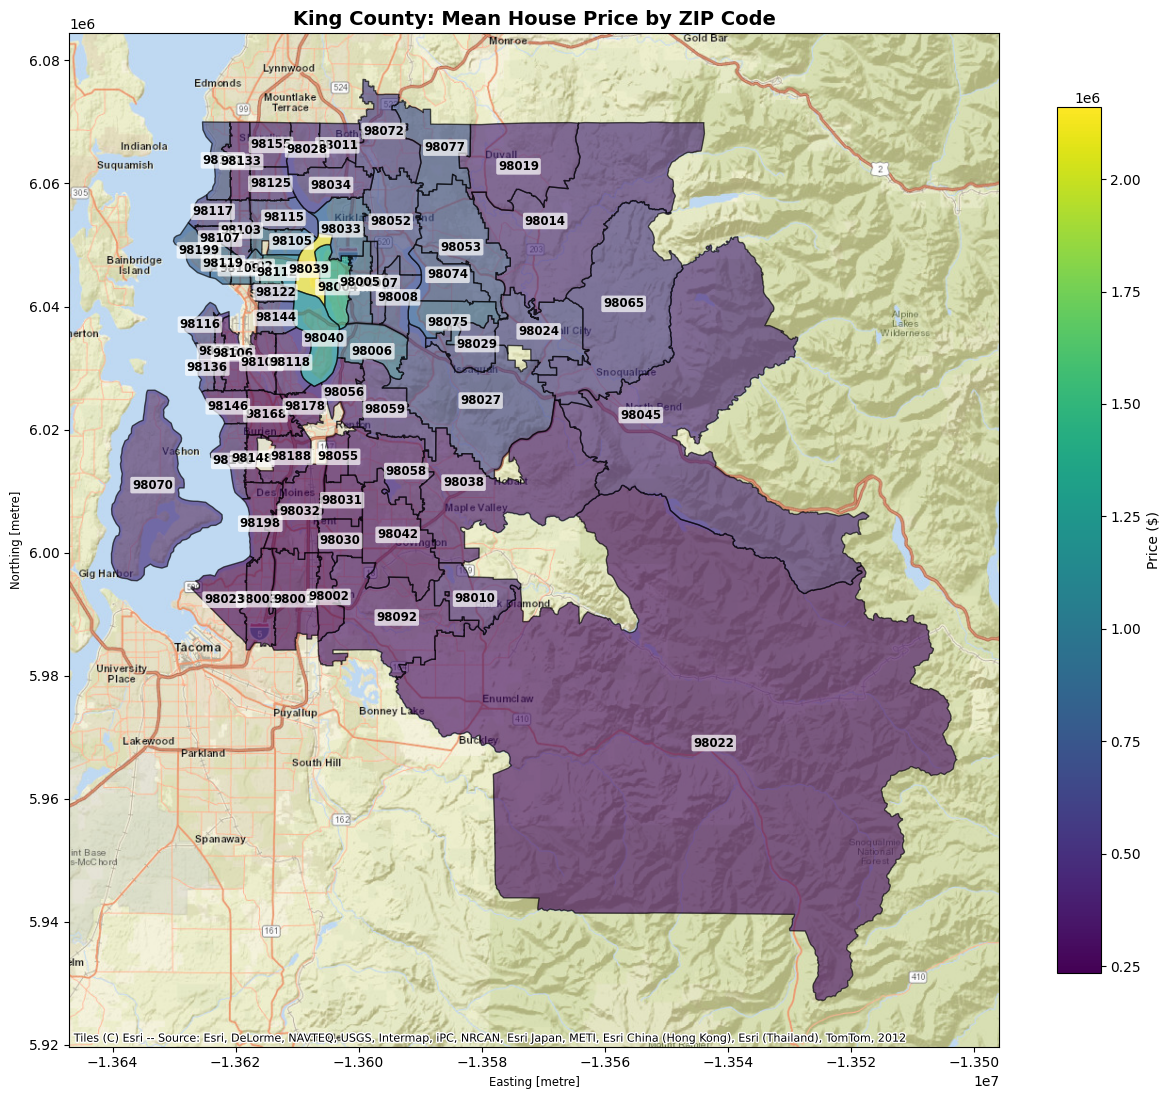